# **CAD-ViT: Coordinate Attention-Enhanced Vision Transformer With Dilated Feature Fusion for Diabetic Retinopathy Staging**

Original Paper: https://ieeexplore.ieee.org/document/11009024

**Dataset Used**

- APTOS 2019
https://www.kaggle.com/datasets/mariaherrerot/aptos2019

- DDR
https://www.kaggle.com/datasets/mariaherrerot/ddrdataset

## 1. Siapkan Library

In [5]:
from google.colab import userdata, drive
from pathlib import Path
from collections import Counter
from PIL import Image, ImageFile, ImageOps
from IPython.display import display

import os
import kagglehub
import shutil
import hashlib
import warnings
import random
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torchvision import transforms
from torchvision.transforms import InterpolationMode

## 2. Dataset Acquisition &amp; Partitioning

In [2]:
# Kaggle authentication
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

# Mount Google Drive
drive.mount("/content/drive")

# Persistent dataset directory
DRIVE_ROOT = "/content/drive/MyDrive/CAD_ViT"
DATA_DIR = os.path.join(DRIVE_ROOT, "datasets")

os.makedirs(DATA_DIR, exist_ok=True)

print("Dataset directory:", DATA_DIR)
print("Existing folders:", os.listdir(DATA_DIR))

Mounted at /content/drive
Dataset directory: /content/drive/MyDrive/CAD_ViT/datasets
Existing folders: ['APTOS', 'DDR']


In [3]:
APTOS_DIR = os.path.join(DATA_DIR, "APTOS")
# Check if the directory exists and contains files
if os.path.exists(APTOS_DIR) and os.listdir(APTOS_DIR):
    print("already exist")
    path_aptos = APTOS_DIR
else:
    os.makedirs(APTOS_DIR, exist_ok=True)
    path_aptos = kagglehub.dataset_download(
        "mariaherrerot/aptos2019",
        output_dir=APTOS_DIR
    )

print("APTOS path:", path_aptos)

already exist
APTOS path: /content/drive/MyDrive/CAD_ViT/datasets/APTOS


In [4]:
DDR_DIR = os.path.join(DATA_DIR, "DDR")
if os.path.exists(DDR_DIR) and os.listdir(DDR_DIR):
    print("already exist")
    path_ddr = DDR_DIR
else:
    os.makedirs(DDR_DIR, exist_ok=True)
    path_ddr = kagglehub.dataset_download(
        "mariaherrerot/ddrdataset",
        output_dir=DDR_DIR
    )

print("DDR path:", path_ddr)

already exist
DDR path: /content/drive/MyDrive/CAD_ViT/datasets/DDR


In [ ]:
shutil.copytree(path_aptos, APTOS_DIR, dirs_exist_ok=True)
shutil.copytree(path_ddr,DDR_DIR,dirs_exist_ok=True)

'/content/drive/MyDrive/CAD_ViT/datasets/DDR'

## 2. Exploratory Data Analysis (EDA) & PreProcessing



1.   EDA cropping : Mendeteksi border hitam
2.   EDA resizing : Rasio dan ukuran image
1.   EDA Gaussian blur : Mengukur ketajaman dan kehilangan detail
2.   EDA data augmentation: Flipping, shearing, dan rotation
1.   EDA summary : Kesimpulan untuk preprocessing







In [8]:
DATA_DIR = Path("/content/drive/MyDrive/CAD_ViT/datasets")
EDA_DIR = Path("/content/drive/MyDrive/CAD_ViT/eda_results")
EDA_DIR.mkdir(parents=True, exist_ok=True)
DATASETS = {
    "APTOS": DATA_DIR / "APTOS",
    "DDR": DATA_DIR / "DDR",
}
IMAGE_EXTENSIONS = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

DR_LABELS = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR",
}

SEED = 42
MAX_QUALITY_SAMPLES = 500

random.seed(SEED)
np.random.seed(SEED)
ImageFile.LOAD_TRUNCATED_IMAGES = False

for name, path in DATASETS.items():
    assert path.is_dir(), f"{name} directory not found: {path}"

def find_fundus_images(root):
    root = Path(root)
    return sorted(
        p for p in Path(root).rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

image_paths = {name: find_fundus_images(path) for name, path in DATASETS.items()}

for name, paths in image_paths.items():
    print(f"{name}: {len(paths):,} images")

print("\nSetup completed.")

APTOS: 3,662 images
DDR: 12,524 images

Setup completed.


In [9]:
# EDA cropping — mendeteksi border hitam
def crop_black_border(image, threshold=10):
    rgb = np.asarray(image.convert("RGB"))
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    mask = gray > threshold
    coords = cv2.findNonZero(mask.astype(np.uint8))

    if coords is None:
        return image.copy(), (0, 0, image.width, image.height)

    x, y, w, h = cv2.boundingRect(coords)
    cropped = image.crop((x, y, x + w, y + h))
    return cropped, (x, y, x + w, y + h)

def get_crop_metrics(image, threshold=10):
    gray = np.asarray(image.convert("L"))
    h, w = gray.shape
    cropped, (x1, y1, x2, y2) = crop_black_border(
        image, threshold=threshold
    )
    crop_w = x2 - x1
    crop_h = y2 - y1

    return {
        "width": w,
        "height": h,
        "aspect_ratio": w / h,
        "black_pixel_ratio": np.mean(gray <= threshold),
        "crop_retention": (crop_w * crop_h) / (w * h),
        "bbox_width_ratio": crop_w / w,
        "bbox_height_ratio": crop_h / h,
        "left_border_ratio": x1 / w,
        "top_border_ratio": y1 / h,
        "right_border_ratio": (w - x2) / w,
        "bottom_border_ratio": (h - y2) / h,
        "bbox_center_offset_x": abs((x1 + x2) / 2 - w / 2) / w,
        "bbox_center_offset_y": abs((y1 + y2) / 2 - h / 2) / h,
    }


def compute_image_eda(paths, dataset_name, max_samples=500):
    selected = list(paths)
    if len(selected) > max_samples:
        selected = random.Random(SEED).sample(selected, max_samples)

    rows = []
    for p in selected:
        try:
            with Image.open(p) as img:
                row = get_crop_metrics(img)
                row["dataset"] = dataset_name
                row["file"] = str(p)
                row["format"] = img.format
                row["mode"] = img.mode
                rows.append(row)
        except Exception as e:
            print(f"Gagal membaca {p}: {e}")

    return pd.DataFrame(rows)


eda_frames = []

for name, paths in image_paths.items():
    df = compute_image_eda(paths, name, MAX_QUALITY_SAMPLES)
    eda_frames.append(df)

eda = pd.concat(eda_frames, ignore_index=True)

display(
    eda.groupby("dataset")[
        [
            "width", "height", "aspect_ratio",
            "black_pixel_ratio", "crop_retention",
            "bbox_width_ratio", "bbox_height_ratio",
            "bbox_center_offset_x", "bbox_center_offset_y"
        ]
    ].agg(["count", "mean", "median", "min", "max"]).round(4)
)

eda.to_csv(EDA_DIR / "cropping_eda.csv", index=False)

width                              height                         \
        count      mean  median  min   max  count      mean  median  min   
dataset                                                                    
APTOS     500  2031.166  2144.0  640  4288    500  1531.350  1536.0  480   
DDR       500   836.322   512.0  512  4496    500   747.128   512.0  512   

               ... bbox_center_offset_x                               \
          max  ...                count    mean  median  min     max   
dataset        ...                                                     
APTOS    2848  ...                  500  0.0109  0.0021  0.0  0.0493   
DDR      3456  ...                  500  0.0019  0.0010  0.0  0.0800   

        bbox_center_offset_y                              
                       count    mean median  min     max  
dataset                                                   
APTOS                    500  0.0014  0.000  0.0  0.0214  
DDR                      500  0.0019  0.001  0.0  0.0202  

[2 rows x 45 columns]

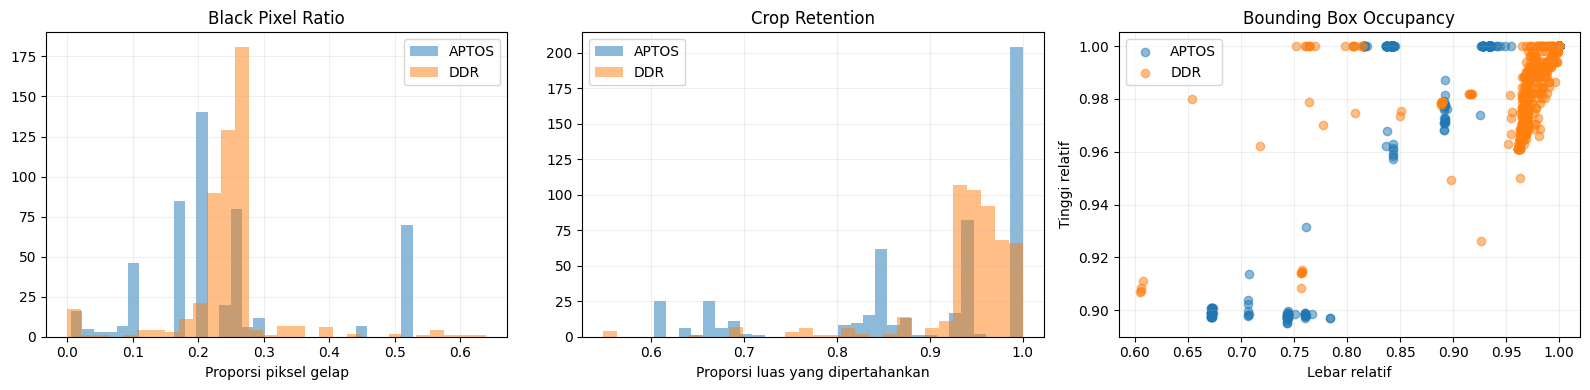

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for dataset in eda["dataset"].unique():
    sub = eda[eda["dataset"] == dataset]
    axes[0].hist(
        sub["black_pixel_ratio"], bins=30, alpha=0.5, label=dataset
    )
    axes[1].hist(
        sub["crop_retention"], bins=30, alpha=0.5, label=dataset
    )
    axes[2].scatter(
        sub["bbox_width_ratio"], sub["bbox_height_ratio"],
        alpha=0.5, label=dataset
    )

axes[0].set_title("Black Pixel Ratio")
axes[0].set_xlabel("Proporsi piksel gelap")
axes[1].set_title("Crop Retention")
axes[1].set_xlabel("Proporsi luas yang dipertahankan")
axes[2].set_title("Bounding Box Occupancy")
axes[2].set_xlabel("Lebar relatif")
axes[2].set_ylabel("Tinggi relatif")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

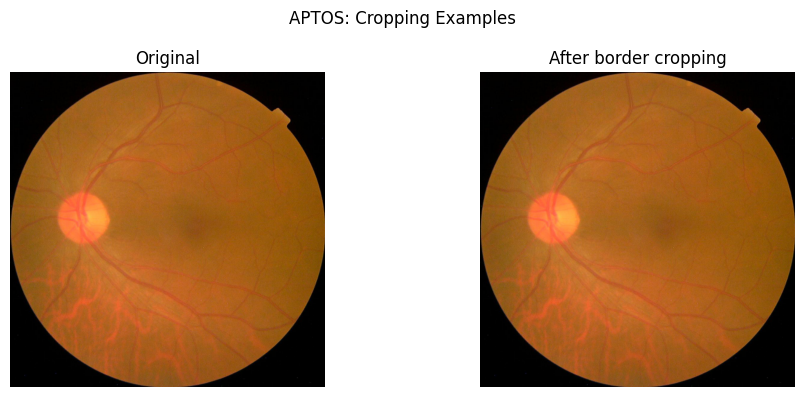

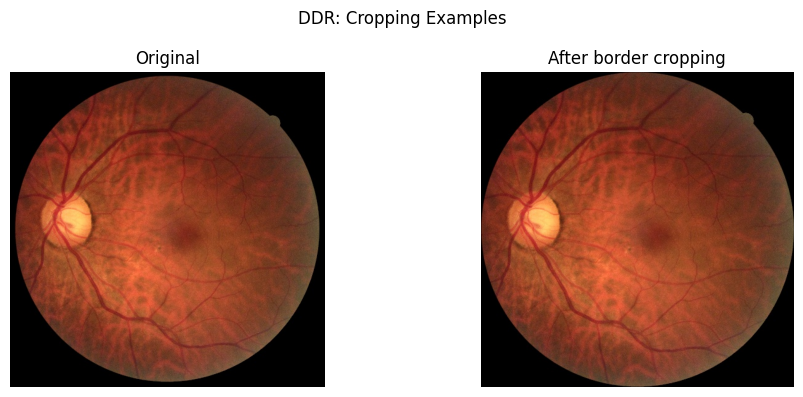

In [11]:
def show_crop_examples(paths, dataset_name, n=1):
    if not paths:
        print(f"Tidak ada gambar untuk {dataset_name}")
        return

    chosen = random.Random(SEED).sample(paths, min(n, len(paths)))

    fig, axes = plt.subplots(len(chosen), 2, figsize=(10, 4 * len(chosen)))
    axes = np.atleast_2d(axes)

    for i, p in enumerate(chosen):
        with Image.open(p) as img:
            img = img.convert("RGB")
            cropped, _ = crop_black_border(img)

            axes[i, 0].imshow(img)
            axes[i, 0].set_title("Original")
            axes[i, 1].imshow(cropped)
            axes[i, 1].set_title("After border cropping")

            axes[i, 0].axis("off")
            axes[i, 1].axis("off")

    plt.suptitle(f"{dataset_name}: Cropping Examples")
    plt.tight_layout()
    plt.show()

for name, paths in image_paths.items():
    show_crop_examples(paths, name)

width                                                            \
         count      mean      std    min     25%     50%     75%     max   
dataset                                                                    
APTOS    500.0  2031.166  887.466  640.0  1050.0  2144.0  2588.0  4288.0   
DDR      500.0   836.322  768.620  512.0   512.0   512.0   512.0  4496.0   

        height            ... scale_to_512_x      scale_to_512_y         \
         count      mean  ...            75%  max          count   mean   
dataset                   ...                                             
APTOS    500.0  1531.350  ...          0.488  0.8          500.0  0.394   
DDR      500.0   747.128  ...          1.000  1.0          500.0  0.879   

                                                   
           std    min    25%    50%    75%    max  
dataset                                            
APTOS    0.185  0.180  0.261  0.333  0.488  1.067  
DDR      0.269  0.148  1.000  1.000  1.000  1.000  

[2 rows x 48 columns]

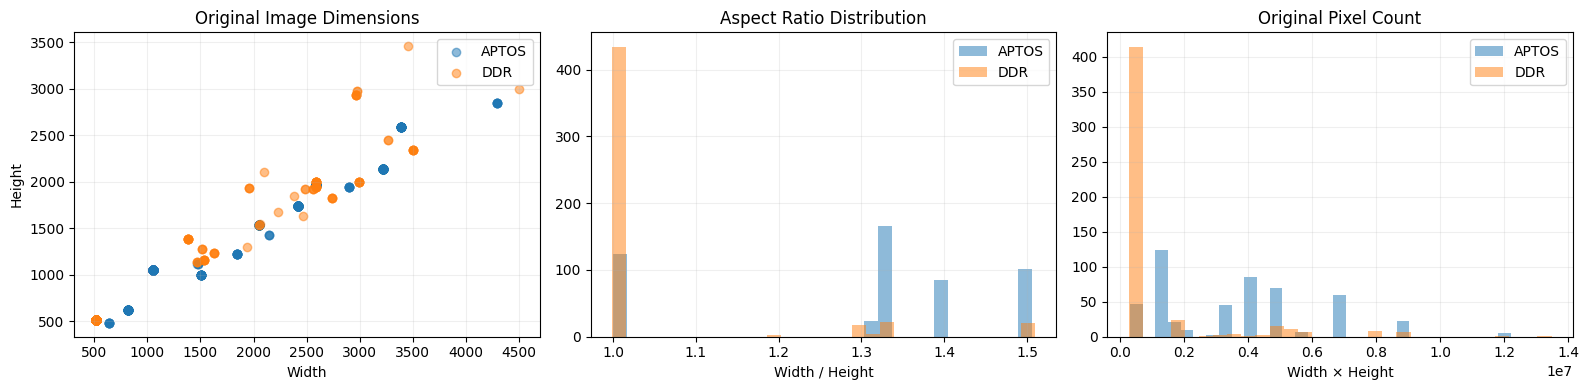

In [12]:
# EDA Resizing
def inspect_resolutions(paths, dataset_name, max_samples=500):
    selected = list(paths)
    if len(selected) > max_samples:
        selected = random.Random(SEED).sample(selected, max_samples)

    rows = []
    for p in selected:
        try:
            with Image.open(p) as img:
                w, h = img.size
                rows.append({
                    "dataset": dataset_name,
                    "file": str(p),
                    "width": w,
                    "height": h,
                    "aspect_ratio": w / h,
                    "pixels": w * h,
                    "scale_to_512_x": 512 / w,
                    "scale_to_512_y": 512 / h,
                })
        except Exception:
            pass

    return pd.DataFrame(rows)

resolution_frames = [
    inspect_resolutions(paths, name)
    for name, paths in image_paths.items()
]
resolution_df = pd.concat(resolution_frames, ignore_index=True)

display(
    resolution_df.groupby("dataset")[
        ["width", "height", "aspect_ratio", "pixels",
         "scale_to_512_x", "scale_to_512_y"]
    ].describe().round(3)
)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for dataset in resolution_df["dataset"].unique():
    sub = resolution_df[resolution_df["dataset"] == dataset]
    axes[0].scatter(sub["width"], sub["height"], alpha=0.5, label=dataset)
    axes[1].hist(sub["aspect_ratio"], bins=30, alpha=0.5, label=dataset)
    axes[2].hist(sub["pixels"], bins=30, alpha=0.5, label=dataset)

axes[0].set_title("Original Image Dimensions")
axes[0].set_xlabel("Width")
axes[0].set_ylabel("Height")
axes[1].set_title("Aspect Ratio Distribution")
axes[1].set_xlabel("Width / Height")
axes[2].set_title("Original Pixel Count")
axes[2].set_xlabel("Width × Height")

for ax in axes:
    ax.legend()
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()
resolution_df.to_csv(EDA_DIR / "resolution_eda.csv", index=False)

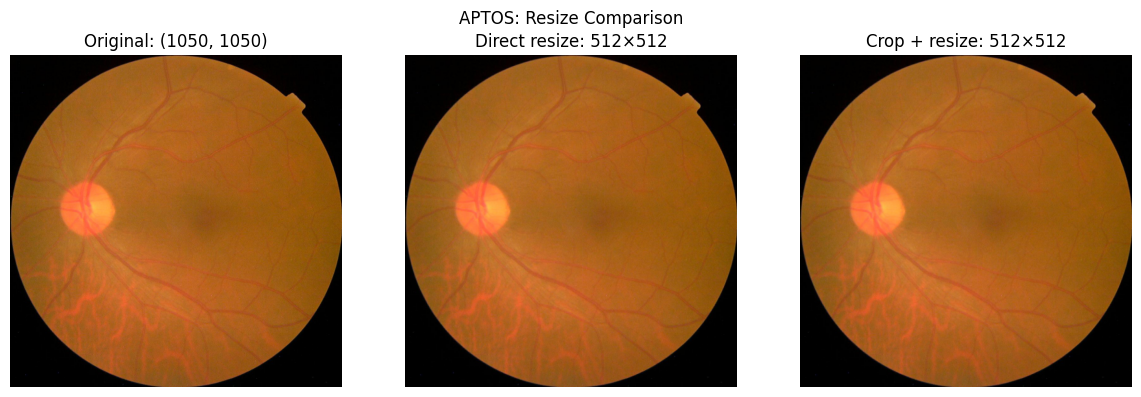

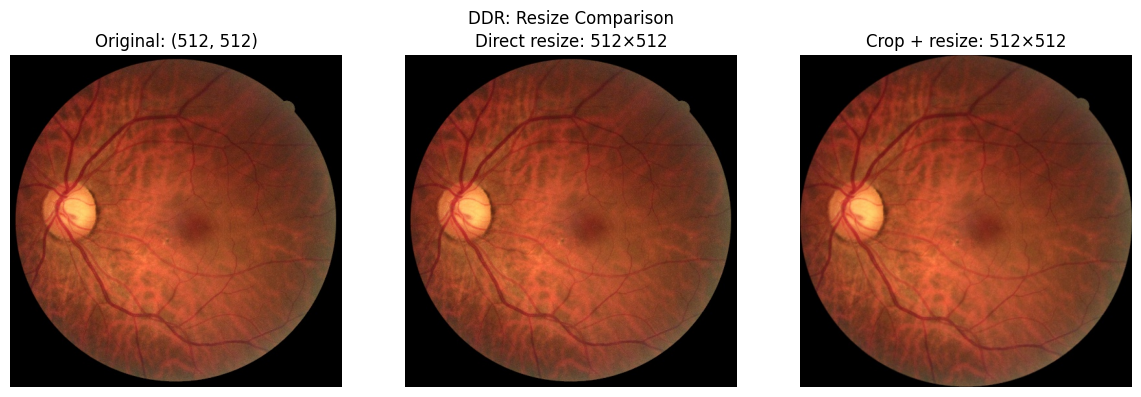

In [13]:
def resize_to_512(image):
    rgb = np.asarray(image.convert("RGB"))
    return cv2.resize(rgb, (512, 512), interpolation=cv2.INTER_AREA)

def show_resize_examples(paths, dataset_name, n=1):
    chosen = random.Random(SEED).sample(paths, min(n, len(paths)))

    fig, axes = plt.subplots(len(chosen), 3, figsize=(12, 4 * len(chosen)))
    axes = np.atleast_2d(axes)

    for i, p in enumerate(chosen):
        with Image.open(p) as img:
            original = img.convert("RGB")
            cropped, _ = crop_black_border(original)
            crop_resize = resize_to_512(cropped)
            direct_resize = resize_to_512(original)

            axes[i, 0].imshow(original)
            axes[i, 0].set_title(f"Original: {original.size}")
            axes[i, 1].imshow(direct_resize)
            axes[i, 1].set_title("Direct resize: 512×512")
            axes[i, 2].imshow(crop_resize)
            axes[i, 2].set_title("Crop + resize: 512×512")

            for ax in axes[i]:
                ax.axis("off")

    plt.suptitle(f"{dataset_name}: Resize Comparison")
    plt.tight_layout()
    plt.show()


for name, paths in image_paths.items():
    show_resize_examples(paths, name)

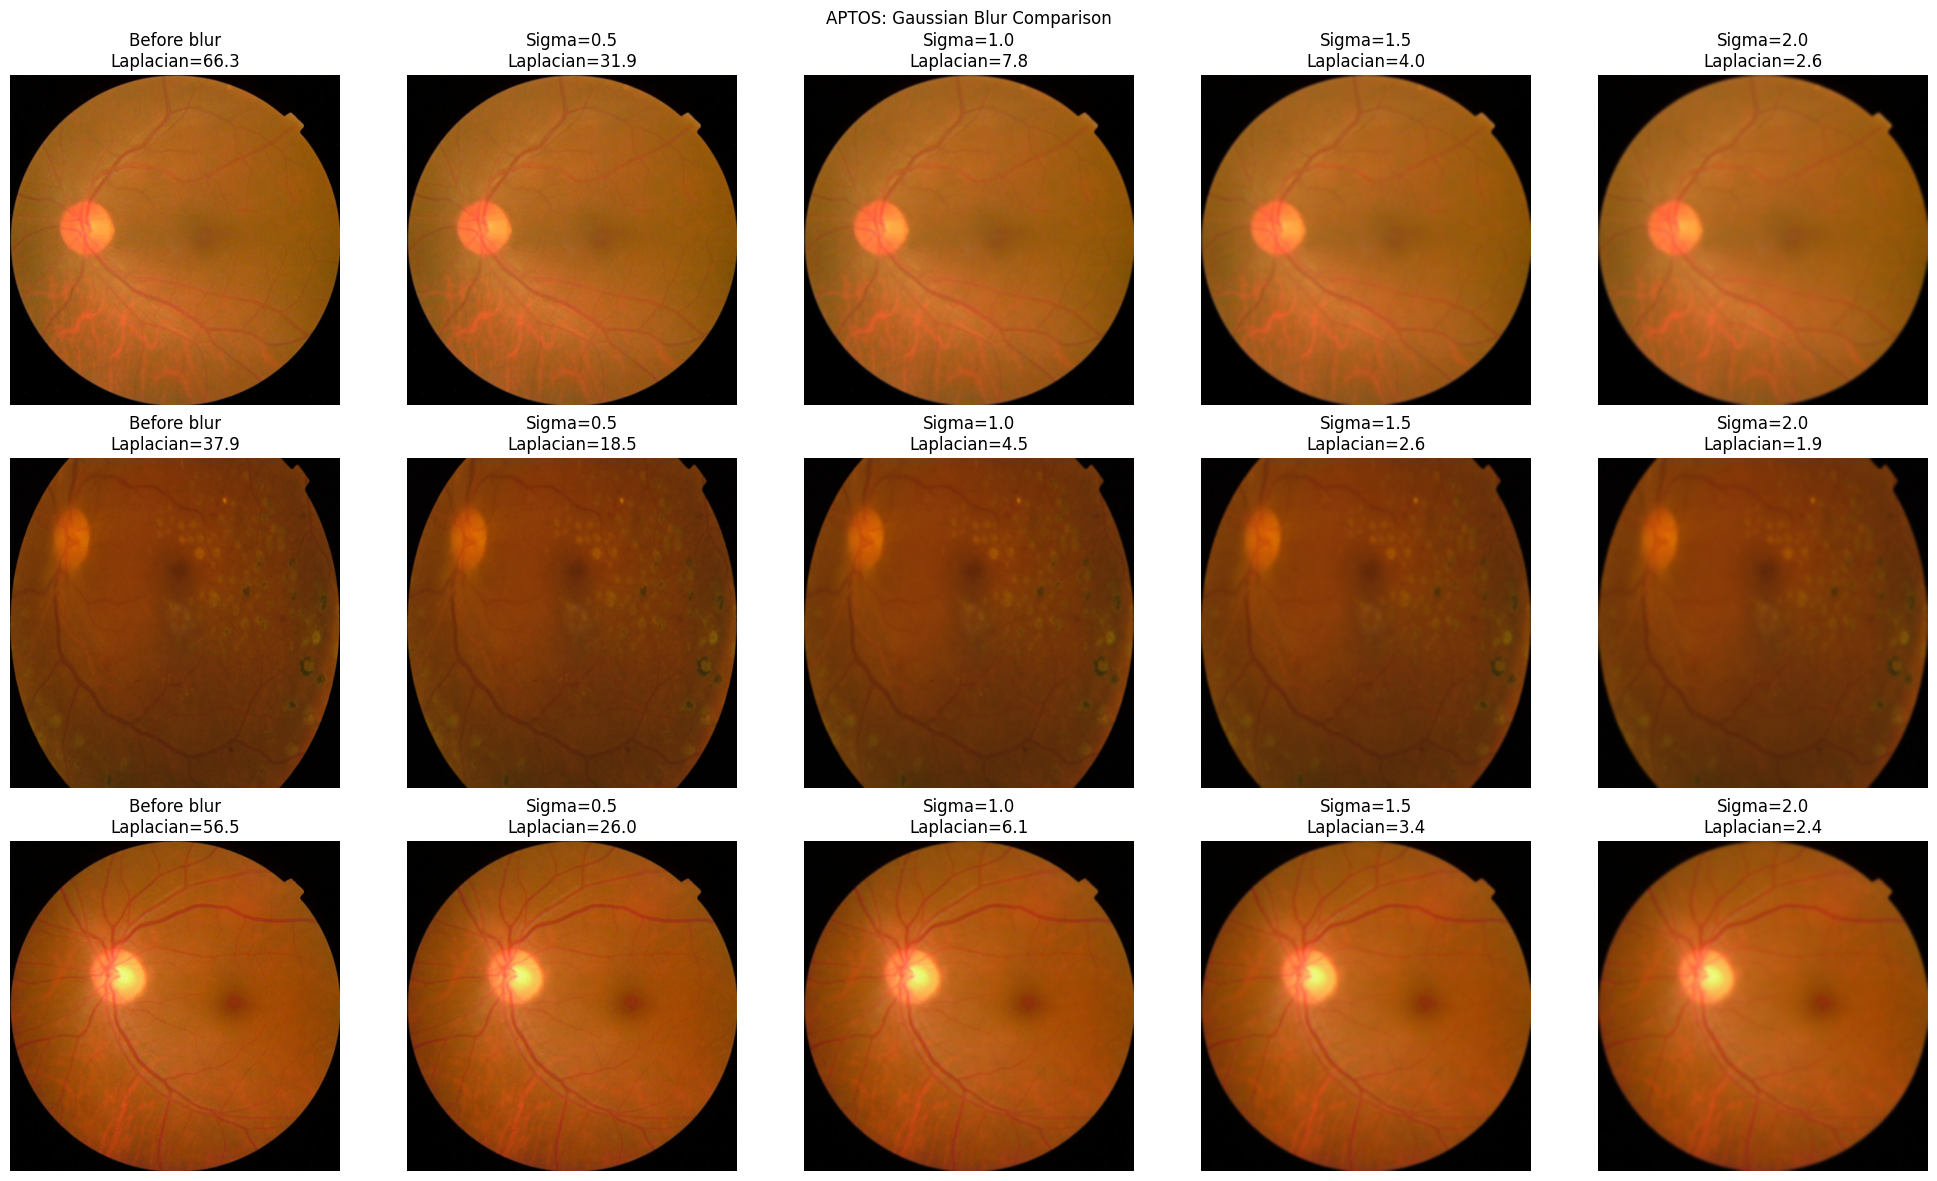

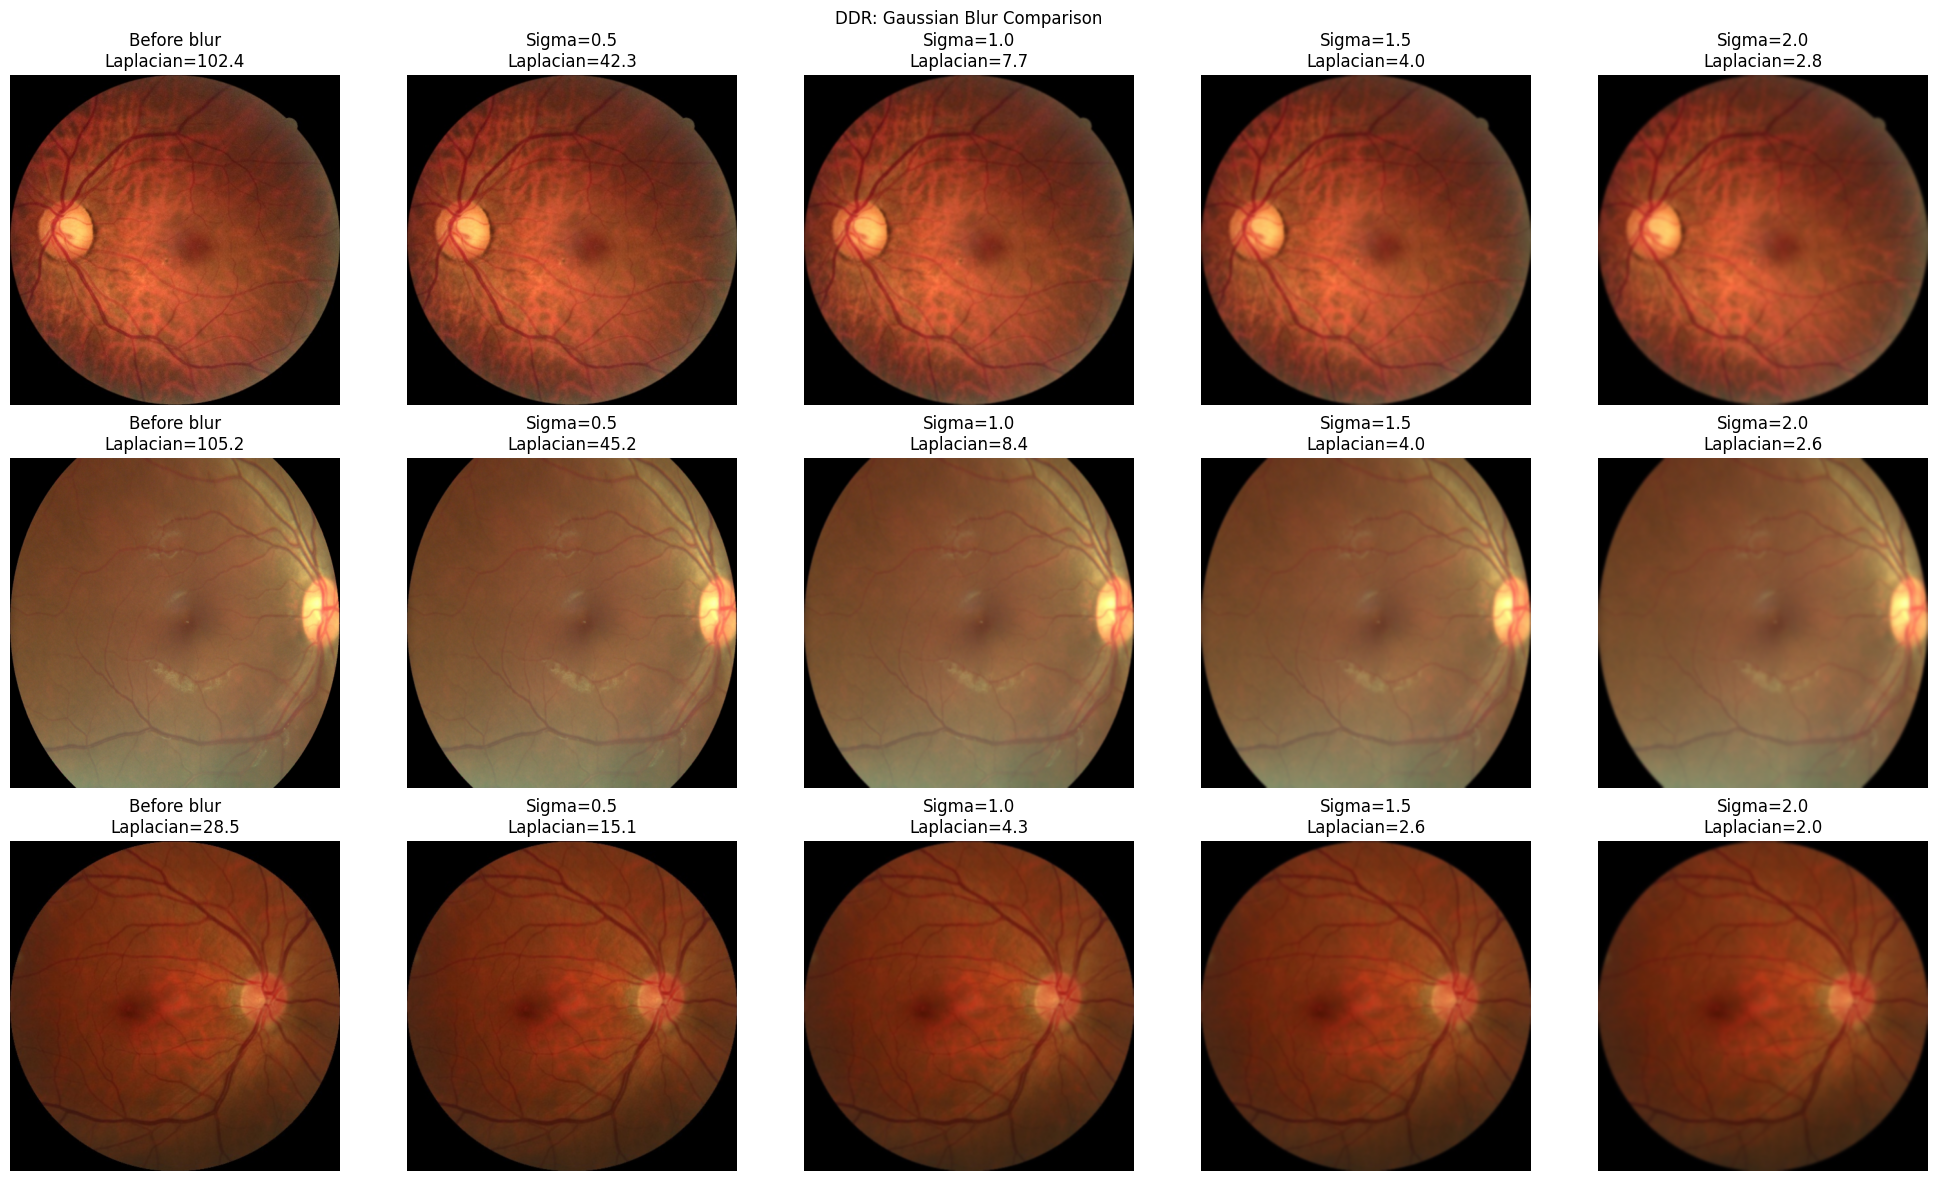

median    mean     std
dataset sigma                         
APTOS   0.0     56.461  53.575  14.416
        0.5     25.990  25.442   6.725
        1.0      6.091   6.116   1.634
        1.5      3.381   3.327   0.691
        2.0      2.423   2.331   0.367
DDR     0.0    102.431  78.721  43.474
        0.5     42.250  34.163  16.610
        1.0      7.695   6.806   2.211
        1.5      3.971   3.526   0.793
        2.0      2.566   2.452   0.422

In [14]:
# EDA Gausian Blur
def sharpness_score(rgb_image):
    gray = cv2.cvtColor(rgb_image, cv2.COLOR_RGB2GRAY)
    return cv2.Laplacian(gray, cv2.CV_64F).var()

def preprocess_for_blur_eda(image):
    cropped, _ = crop_black_border(image)
    return resize_to_512(cropped)

def compare_blur(paths, dataset_name, n=3, sigmas=(0.5, 1.0, 1.5, 2.0)):
    chosen = random.Random(SEED).sample(paths, min(n, len(paths)))
    rows = []
    fig, axes = plt.subplots(
        len(chosen), len(sigmas) + 1,
        figsize=(4 * (len(sigmas) + 1), 4 * len(chosen))
    )
    axes = np.atleast_2d(axes)
    for i, p in enumerate(chosen):
        with Image.open(p) as img:
            base = preprocess_for_blur_eda(img)
        axes[i, 0].imshow(base)
        axes[i, 0].set_title(
            f"Before blur\nLaplacian={sharpness_score(base):.1f}"
        )
        axes[i, 0].axis("off")
        rows.append({
            "dataset": dataset_name,
            "file": str(p),
            "sigma": 0,
            "laplacian_variance": sharpness_score(base),
        })
        for j, sigma in enumerate(sigmas, start=1):
            blurred = cv2.GaussianBlur(
                base, (0, 0), sigmaX=sigma, sigmaY=sigma
            )
            axes[i, j].imshow(blurred)
            axes[i, j].set_title(
                f"Sigma={sigma}\n"
                f"Laplacian={sharpness_score(blurred):.1f}"
            )
            axes[i, j].axis("off")
            rows.append({
                "dataset": dataset_name,
                "file": str(p),
                "sigma": sigma,
                "laplacian_variance": sharpness_score(blurred),
            })
    plt.suptitle(f"{dataset_name}: Gaussian Blur Comparison")
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(rows)

blur_frames = []
for name, paths in image_paths.items():
    if paths:
        blur_frames.append(compare_blur(paths, name))

blur_df = pd.concat(blur_frames, ignore_index=True)
display(
    blur_df.groupby(["dataset", "sigma"])["laplacian_variance"]
    .agg(["median", "mean", "std"])
    .round(3)
)

blur_df.to_csv(EDA_DIR / "gaussian_blur_eda.csv", index=False)

In [15]:
ROTATION_ANGLE = 15
SHEAR_ANGLE = 10
IMAGE_SIZE = 512

def visualize_augmentation(image_path, gaussian_sigma=None):
    with Image.open(image_path) as img:
        original = img.convert("RGB")

    if gaussian_sigma is not None:
        processed_array = preprocess_fundus(
            original, gaussian_sigma
        )
        base_image = Image.fromarray(processed_array)
    else:
        base_image = original.resize(
            (IMAGE_SIZE, IMAGE_SIZE),
            resample=Image.Resampling.BOX
        )

    augmentation_examples = {
        "Original": transforms.Compose([]),
        "Horizontal Flip": transforms.RandomHorizontalFlip(p=1.0),
        "Vertical Flip": transforms.RandomVerticalFlip(p=1.0),
        "Rotation +15°": transforms.RandomRotation(
            degrees=(ROTATION_ANGLE, ROTATION_ANGLE),
            interpolation=InterpolationMode.BILINEAR,
            fill=0
        ),
        "Rotation -15°": transforms.RandomRotation(
            degrees=(-ROTATION_ANGLE, -ROTATION_ANGLE),
            interpolation=InterpolationMode.BILINEAR,
            fill=0
        ),
        "Shear +10°": transforms.RandomAffine(
            degrees=0,
            shear=(SHEAR_ANGLE, SHEAR_ANGLE),
            interpolation=InterpolationMode.BILINEAR,
            fill=0
        ),
        "Shear -10°": transforms.RandomAffine(
            degrees=0,
            shear=(-SHEAR_ANGLE, -SHEAR_ANGLE),
            interpolation=InterpolationMode.BILINEAR,
            fill=0
        ),
    }
    fig, axes = plt.subplots(2, 4, figsize=(16, 9))
    axes = axes.flatten()
    for ax, (title, transform) in zip(
        axes, augmentation_examples.items()
    ):
        augmented_image = transform(base_image)
        ax.imshow(augmented_image)
        ax.set_title(title, fontsize=12)
        ax.axis("off")

    fig.suptitle(
        "Fundus Image Data Augmentation",
        fontsize=16,
        fontweight="bold"
    )
    plt.tight_layout()
    plt.show()

In [16]:
# Ringkasan karakteristik gambar
summary = eda.groupby("dataset").agg(
    sampled_images=("file", "count"),
    median_width=("width", "median"),
    median_height=("height", "median"),
    median_aspect_ratio=("aspect_ratio", "median"),
    median_black_pixel_ratio=("black_pixel_ratio", "median"),
    median_crop_retention=("crop_retention", "median"),
    median_bbox_width_ratio=("bbox_width_ratio", "median"),
    median_bbox_height_ratio=("bbox_height_ratio", "median"),
).round(4)

display(summary)

summary.to_csv(EDA_DIR / "preprocessing_eda_summary.csv")

print("EDA selesai. File tersimpan di:", EDA_DIR)
print("File yang dihasilkan:")
for p in sorted(EDA_DIR.glob("*.csv")):
    print("-", p.name)

,sampled_images,median_width,median_height,median_aspect_ratio,median_black_pixel_ratio,median_crop_retention,median_bbox_width_ratio,median_bbox_height_ratio
dataset,,,,,,,,
APTOS,500,2144.0,1536.0,1.3333,0.2091,0.9342,0.9342,1.0000
DDR,500,512.0,512.0,1.0000,0.2509,0.9498,0.9688,0.9818


EDA selesai. File tersimpan di: /content/drive/MyDrive/CAD_ViT/eda_results
File yang dihasilkan:
- cropping_eda.csv
- gaussian_blur_eda.csv
- preprocessing_eda_summary.csv
- resolution_eda.csv


## 3. Preprocessing, Resampling, and Augmentation

## 4. CAD-ViT model

## 5. Training

## 6. Evaluation
Compute accuracy, precision, recall, F1-score, and specificity